# Tugas - Klasifikasi dengan Support Vector Machine (SVM)

| Nama | NRP |
|------|-----|
| Prima Surya Nusantara | 5054251036 |

## Deskripsi Tugas
Pada tugas ini, kalian akan membangun model SVM Classifier untuk menyelesaikan sebuah masalah klasifikasi.

Dataset dapat diakses melalui link berikut:
[Link dataset akan diinformasikan terpisah]

Tujuan utama dari tugas ini adalah memahami cara kerja SVM secara praktik, khususnya:
1. Perbedaan hasil antara kernel Linear dan kernel RBF
2. Pengaruh parameter `C` dan `gamma` terhadap gejala overfitting/underfitting

Langkah-langkah yang harus dilakukan antara lain:
1. Persiapan Dataset dan Eksplorasi Awal
   - Memuat dataset, melihat struktur data, dan distribusi label.
2. Preprocessing
   - Memproses data agar siap digunakan dalam membangun model, termasuk feature scaling.
3. Eksperimen Model
   - Bangun model SVM dengan kernel Linear dan kernel RBF.
   - Lakukan eksperimen regularisasi dengan variasi nilai `C` dan `gamma`.
4. Evaluasi Model
   - Hitung metrik evaluasi dan visualisasikan hasilnya.
5. Analisis dan Kesimpulan
   - Bandingkan hasil eksperimen dan berikan kesimpulan.

# 1. Persiapan Dataset dan Eksplorasi Awal

In [1]:
from pathlib import Path
import kagglehub
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
from sklearn.decomposition import PCA
from sklearn.base import clone

RANDOM_STATE = 42
sns.set_theme(style="whitegrid")


c:\Users\prima\Tugas Kuliah\Semester 3\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
path = kagglehub.dataset_download("blastchar/telco-customer-churn")
file_csv = Path(path) / "WA_Fn-UseC_-Telco-Customer-Churn.csv"
df = pd.read_csv(file_csv)
display(df.head())
df.info()
print("Jumlah baris dan kolom:", df.shape)
print("Jumlah baris duplikat:", df.duplicated().sum())
print("Missing saat dibaca:")
display(df.isna().sum())

kolom_numerik = ["tenure", "MonthlyCharges", "TotalCharges"]
kolom_kategorikal = [c for c in df.columns if c not in kolom_numerik + ["customerID", "Churn"]]
numerik = df[kolom_numerik].apply(pd.to_numeric, errors="coerce")
statistik = numerik.describe().T.rename(columns={"50%": "median"})
statistik["modus"] = numerik.mode().iloc[0]
statistik["IQR"] = statistik["75%"] - statistik["25%"]
statistik["skewness"] = numerik.skew()
display(statistik)
display(df[kolom_kategorikal].astype("category").describe().T)
print("Missing setelah konversi numerik:")
display(numerik.isna().sum())


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

,count,mean,std,min,25%,median,75%,max,modus,IQR,skewness
tenure,7043.0,32.371149,24.559481,0.00,9.00,29.000,55.0000,72.00,1.00,46.0000,0.239540
MonthlyCharges,7043.0,64.761692,30.090047,18.25,35.50,70.350,89.8500,118.75,20.05,54.3500,-0.220524
TotalCharges,7032.0,2283.300441,2266.771362,18.80,401.45,1397.475,3794.7375,8684.80,20.20,3393.2875,0.961642


,count,unique,top,freq
gender,7043,2,Male,3555
SeniorCitizen,7043,2,0,5901
Partner,7043,2,No,3641
Dependents,7043,2,No,4933
PhoneService,7043,2,Yes,6361
MultipleLines,7043,3,No,3390
InternetService,7043,3,Fiber optic,3096
OnlineSecurity,7043,3,No,3498
OnlineBackup,7043,3,No,3088
DeviceProtection,7043,3,No,3095


Missing setelah konversi numerik:


tenure             0
MonthlyCharges     0
TotalCharges      11
dtype: int64

,Jumlah,Persentase (%)
Churn,,
No,5174,73.463013
Yes,1869,26.536987


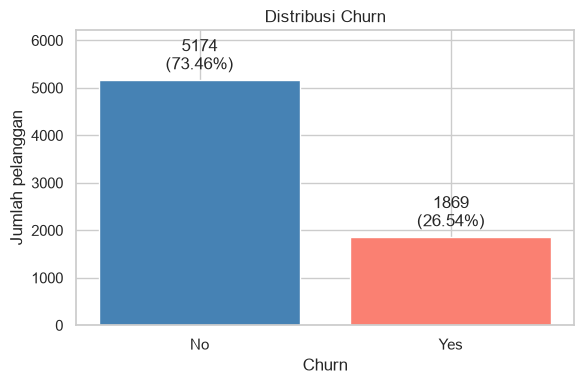

In [3]:
jumlah = df["Churn"].value_counts().reindex(["No", "Yes"], fill_value=0)
display(pd.DataFrame({"Jumlah": jumlah, "Persentase (%)": jumlah / jumlah.sum() * 100}))
fig, ax = plt.subplots(figsize=(6, 4))
batang = ax.bar(jumlah.index, jumlah.values, color=["steelblue", "salmon"])
ax.bar_label(batang, labels=[f"{v}\n({v / jumlah.sum():.2%})" for v in jumlah], padding=4)
ax.set(title="Distribusi Churn", xlabel="Churn", ylabel="Jumlah pelanggan", ylim=(0, jumlah.max() * 1.2))
plt.tight_layout()
plt.show()


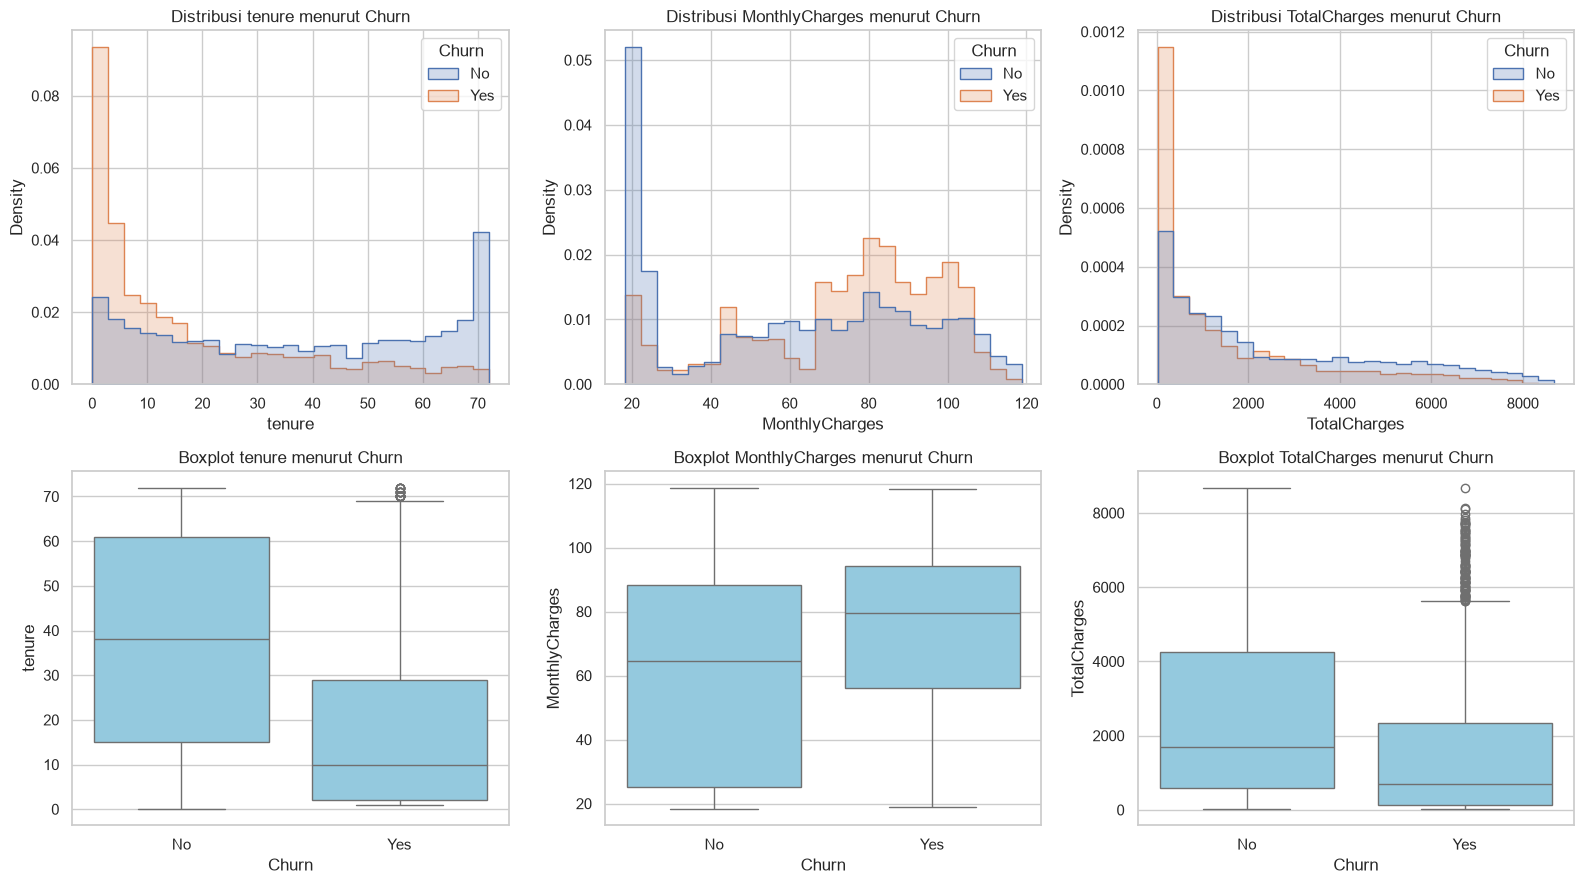

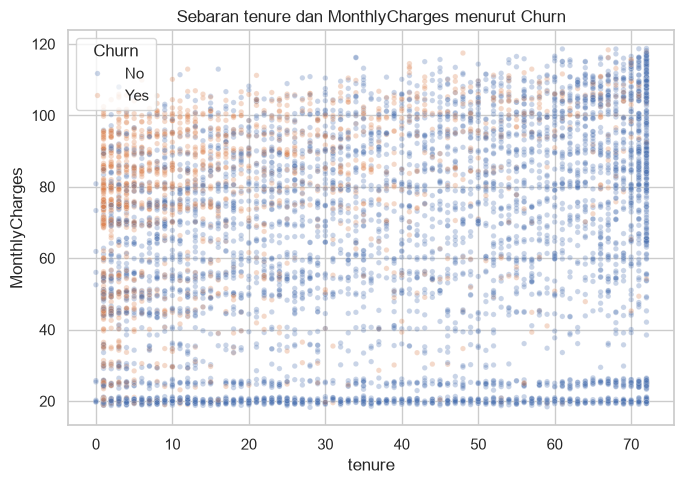

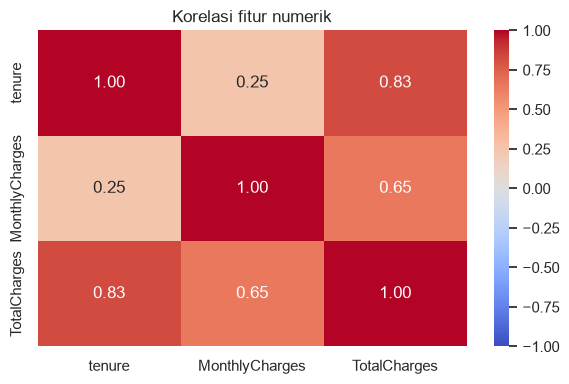

Churn,No,Yes
Contract,,
Month-to-month,57.29,42.71
One year,88.73,11.27
Two year,97.17,2.83


In [4]:
data_eda = numerik.join(df["Churn"])
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for j, kolom in enumerate(kolom_numerik):
    sns.histplot(data=data_eda, x=kolom, hue="Churn", bins=25,
            stat="density", common_norm=False, element="step", ax=axes[0, j])
    sns.boxplot(data=data_eda, x="Churn", y=kolom, order=["No", "Yes"],
                color="skyblue", ax=axes[1, j])
    axes[0, j].set_title(f"Distribusi {kolom} menurut Churn")
    axes[1, j].set_title(f"Boxplot {kolom} menurut Churn")
plt.tight_layout()
plt.show()

plt.figure(figsize=(7, 5))
sns.scatterplot(data=data_eda, x="tenure", y="MonthlyCharges", hue="Churn", alpha=0.3, s=15)
plt.title("Sebaran tenure dan MonthlyCharges menurut Churn")
plt.tight_layout()
plt.show()
plt.figure(figsize=(6, 4))
sns.heatmap(numerik.corr(), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Korelasi fitur numerik")
plt.tight_layout()
plt.show()

tabel_kontrak = pd.crosstab(df["Contract"], df["Churn"], normalize="index") * 100
display(tabel_kontrak.round(2))


## Lakukan Exploratory Data Analysis (EDA) tambahan yang diperlukan.

# 2. Preprocessing

In [5]:
df_preprocessing = df.copy()
df_preprocessing[kolom_numerik] = df_preprocessing[kolom_numerik].apply(pd.to_numeric, errors="coerce")
df_preprocessing[kolom_kategorikal] = df_preprocessing[kolom_kategorikal].replace(r"^\s*$", np.nan, regex=True)
imputer_numerik = SimpleImputer(strategy="median")
imputer_kategorikal = SimpleImputer(strategy="most_frequent")
display(df_preprocessing.isna().sum())


customerID           0
gender               0
SeniorCitizen        0
Partner              0
Dependents           0
tenure               0
PhoneService         0
MultipleLines        0
InternetService      0
OnlineSecurity       0
OnlineBackup         0
DeviceProtection     0
TechSupport          0
StreamingTV          0
StreamingMovies      0
Contract             0
PaperlessBilling     0
PaymentMethod        0
MonthlyCharges       0
TotalCharges        11
Churn                0
dtype: int64

In [6]:
encoder = OneHotEncoder(handle_unknown="ignore", sparse_output=False)

print("Fitur kategorikal:", kolom_kategorikal)

Fitur kategorikal: ['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']


In [7]:
X = df_preprocessing[kolom_numerik + kolom_kategorikal].copy()
y = df_preprocessing["Churn"].map({"No": 0, "Yes": 1})
if y.isna().any():
    raise ValueError("Target kosong atau memiliki label selain No/Yes.")
y = y.astype(int)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)
print("Ukuran train:", X_train.shape, "Ukuran test:", X_test.shape)
display(pd.DataFrame({
    "Train (%)": y_train.value_counts(normalize=True).sort_index() * 100,
    "Test (%)": y_test.value_counts(normalize=True).sort_index() * 100
}).round(2))


Ukuran train: (5634, 19) Ukuran test: (1409, 19)


,Train (%),Test (%)
Churn,,
0,73.46,73.46
1,26.54,26.54


**Catatan penting:** SVM adalah algoritma berbasis jarak (margin dihitung dari posisi antar titik data), sehingga sangat sensitif terhadap skala fitur. Fitur dengan rentang nilai besar bisa mendominasi perhitungan jarak meskipun sebenarnya tidak lebih penting. Lakukan **feature scaling** (misalnya `StandardScaler`) pada fitur numerik sebelum training. Ingat: `fit` scaler hanya pada train set, lalu `transform` ke train dan test set, agar tidak terjadi data leakage.

In [8]:
preprocessor = ColumnTransformer([
    ("numerik", Pipeline([("imputer", imputer_numerik), ("scaler", StandardScaler())]), kolom_numerik),
    ("kategorikal", Pipeline([("imputer", imputer_kategorikal), ("encoder", encoder)]), kolom_kategorikal)
])
X_train_scaled = preprocessor.fit_transform(X_train)
X_test_scaled = preprocessor.transform(X_test)
print("Train setelah preprocessing:", X_train_scaled.shape)
print("Test setelah preprocessing:", X_test_scaled.shape)
print("Missing train/test:", np.isnan(X_train_scaled).sum(), np.isnan(X_test_scaled).sum())
display(pd.DataFrame(X_train_scaled, columns=preprocessor.get_feature_names_out(), index=X_train.index).head())


Train setelah preprocessing: (5634, 46)
Test setelah preprocessing: (1409, 46)
Missing train/test: 0 0


,numerik__tenure,numerik__MonthlyCharges,numerik__TotalCharges,kategorikal__gender_Female,kategorikal__gender_Male,kategorikal__SeniorCitizen_0,kategorikal__SeniorCitizen_1,kategorikal__Partner_No,kategorikal__Partner_Yes,kategorikal__Dependents_No,...,kategorikal__StreamingMovies_Yes,kategorikal__Contract_Month-to-month,kategorikal__Contract_One year,kategorikal__Contract_Two year,kategorikal__PaperlessBilling_No,kategorikal__PaperlessBilling_Yes,kategorikal__PaymentMethod_Bank transfer (automatic),kategorikal__PaymentMethod_Credit card (automatic),kategorikal__PaymentMethod_Electronic check,kategorikal__PaymentMethod_Mailed check
3738,0.102371,-0.521976,-0.263290,0.0,1.0,1.0,0.0,1.0,0.0,1.0,...,1.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0
3151,-0.711743,0.337478,-0.504815,0.0,1.0,1.0,0.0,0.0,1.0,0.0,...,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0
4860,-0.793155,-0.809013,-0.751214,0.0,1.0,1.0,0.0,0.0,1.0,0.0,...,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,1.0
3867,-0.263980,0.284384,-0.173700,1.0,0.0,1.0,0.0,0.0,1.0,1.0,...,1.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0
3810,-1.281624,-0.676279,-0.990851,0.0,1.0,1.0,0.0,0.0,1.0,0.0,...,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0


# 3. Eksperimen Model

## 3.1 SVM dengan Kernel Linear

Kernel Linear mencari hyperplane pemisah berupa garis/bidang lurus, tanpa proyeksi ke dimensi yang lebih tinggi. Cocok digunakan sebagai baseline, terutama jika dari hasil EDA data terlihat cukup terpisah secara linear.

In [9]:
C_BASELINE = 1.0
model_linear = SVC(kernel="linear", C=C_BASELINE, random_state=RANDOM_STATE)
model_linear.fit(X_train_scaled, y_train)
print("Training SVM Linear selesai.")


Training SVM Linear selesai.


In [10]:
y_pred_linear = model_linear.predict(X_test_scaled)
print(f"Akurasi train Linear: {model_linear.score(X_train_scaled, y_train):.4f}")
print(f"Akurasi test Linear : {accuracy_score(y_test, y_pred_linear):.4f}")


Akurasi train Linear: 0.8007
Akurasi test Linear : 0.7878


## 3.2 SVM dengan Kernel RBF

Kernel RBF (Radial Basis Function) memproyeksikan data ke ruang berdimensi lebih tinggi melalui kernel trick, sehingga mampu menangani batas keputusan yang non-linear.

In [11]:
model_rbf = SVC(kernel="rbf", C=C_BASELINE, gamma="scale", random_state=RANDOM_STATE)
model_rbf.fit(X_train_scaled, y_train)
print("Training SVM RBF selesai.")


Training SVM RBF selesai.


In [12]:
y_pred_rbf = model_rbf.predict(X_test_scaled)
print(f"Akurasi train RBF: {model_rbf.score(X_train_scaled, y_train):.4f}")
print(f"Akurasi test RBF : {accuracy_score(y_test, y_pred_rbf):.4f}")


Akurasi train RBF: 0.8218
Akurasi test RBF : 0.7906


## 3.3 Eksperimen Regularisasi: Pengaruh C dan Gamma terhadap Overfitting

Parameter `C` mengatur trade-off antara margin lebar dan toleransi kesalahan klasifikasi, sedangkan `gamma` (khusus kernel RBF) mengatur seberapa lokal pengaruh tiap titik data. Pada bagian ini kalian akan mengamati bagaimana perubahan nilai `C` (dan/atau `gamma`) memengaruhi akurasi training dan testing.

In [13]:
daftar_C = [0.01, 0.1, 1, 10, 100]
model_variasi_C = {}
for nilai_C in daftar_C:
    model = SVC(kernel="rbf", C=nilai_C, gamma="scale", random_state=RANDOM_STATE)
    model.fit(X_train_scaled, y_train)
    model_variasi_C[nilai_C] = model
    print(f"Training RBF C={nilai_C} selesai.")

Training RBF C=0.01 selesai.
Training RBF C=0.1 selesai.
Training RBF C=1 selesai.
Training RBF C=10 selesai.
Training RBF C=100 selesai.


In [14]:
hasil_C = []
for nilai_C, model in model_variasi_C.items():
    hasil_C.append({
        "C": nilai_C,
        "Akurasi Train": model.score(X_train_scaled, y_train),
        "Akurasi Test": model.score(X_test_scaled, y_test),
        "Jumlah Support Vectors": len(model.support_vectors_)
    })
tabel_C = pd.DataFrame(hasil_C)
tabel_C["Gap Train-Test"] = tabel_C["Akurasi Train"] - tabel_C["Akurasi Test"]
display(tabel_C.round(4))
C_terbaik = float(tabel_C.loc[tabel_C["Akurasi Test"].idxmax(), "C"])
print("C dengan akurasi test tertinggi pada eksperimen:", C_terbaik)
print("Catatan: pemilihan berdasarkan test bersifat eksploratif; gunakan validasi/CV")
print("untuk tuning dan test terpisah untuk evaluasi akhir yang independen.")


,C,Akurasi Train,Akurasi Test,Jumlah Support Vectors,Gap Train-Test
0,0.01,0.7368,0.7360,3013,0.0008
1,0.10,0.8017,0.7913,2692,0.0104
2,1.00,0.8218,0.7906,2649,0.0312
3,10.00,0.8600,0.7821,2718,0.0778
4,100.00,0.9265,0.7615,2647,0.1650


C dengan akurasi test tertinggi pada eksperimen: 0.1
Catatan: pemilihan berdasarkan test bersifat eksploratif; gunakan validasi/CV
untuk tuning dan test terpisah untuk evaluasi akhir yang independen.


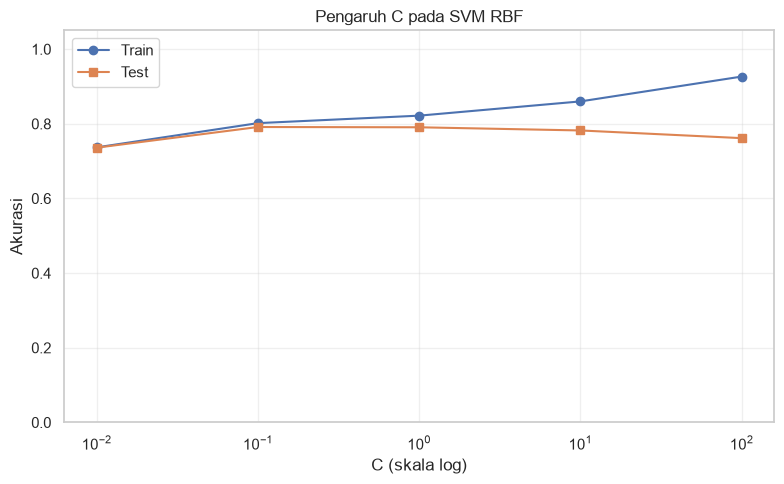

Pembanding mayoritas train pada test: 0.7345635202271115


In [15]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(tabel_C["C"], tabel_C["Akurasi Train"], marker="o", label="Train")
ax.plot(tabel_C["C"], tabel_C["Akurasi Test"], marker="s", label="Test")
ax.set_xscale("log")
ax.set(xlabel="C (skala log)", ylabel="Akurasi", title="Pengaruh C pada SVM RBF", ylim=(0, 1.05))
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()
print("Pembanding mayoritas train pada test:", accuracy_score(
    y_test, np.full(len(y_test), y_train.mode().iloc[0])
))


# 4. Evaluasi Model

In [16]:
model_evaluasi = {"Linear (C=1)": model_linear, "RBF (C=1)": model_rbf}
prediksi_evaluasi = {"Linear (C=1)": y_pred_linear, "RBF (C=1)": y_pred_rbf}
hasil_evaluasi = []
for nama, model in model_evaluasi.items():
    prediksi = prediksi_evaluasi[nama]
    hasil_evaluasi.append({
        "Model": nama,
        "Accuracy": accuracy_score(y_test, prediksi),
        "Precision": precision_score(y_test, prediksi, zero_division=0),
        "Recall": recall_score(y_test, prediksi, zero_division=0),
        "F1-Score": f1_score(y_test, prediksi, zero_division=0)
    })
tabel_evaluasi = pd.DataFrame(hasil_evaluasi)
display(tabel_evaluasi.round(4))
print("Precision, recall, F1: kelas positif 1 = churn; metrik tak terdefinisi diisi 0.")
nama_terbaik = tabel_evaluasi.loc[tabel_evaluasi["Accuracy"].idxmax(), "Model"]
model_terbaik = model_evaluasi[nama_terbaik]
print("Baseline terbaik menurut accuracy test:", nama_terbaik)


,Model,Accuracy,Precision,Recall,F1-Score
0,Linear (C=1),0.7878,0.6176,0.5267,0.5685
1,RBF (C=1),0.7906,0.6386,0.4866,0.5524


Precision, recall, F1: kelas positif 1 = churn; metrik tak terdefinisi diisi 0.
Baseline terbaik menurut accuracy test: RBF (C=1)


Linear (C=1): TN=913, FP=122, FN=177, TP=197
RBF (C=1): TN=932, FP=103, FN=192, TP=182


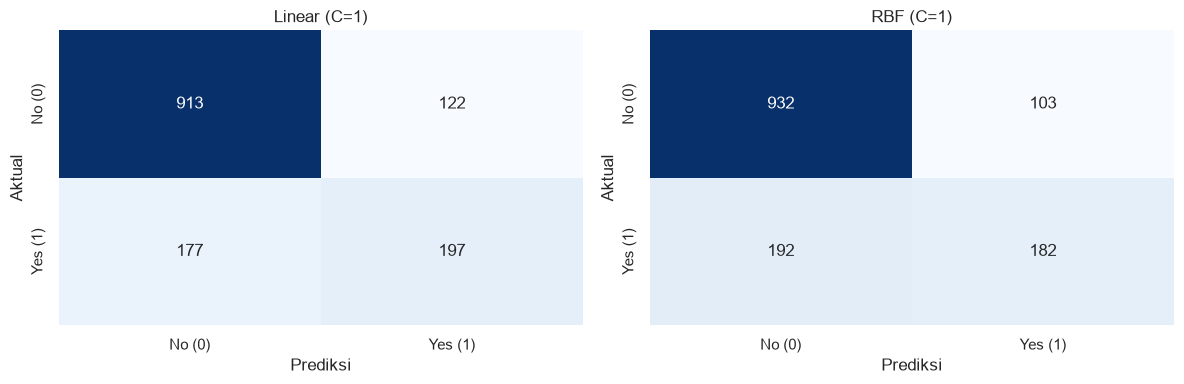

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, (nama, prediksi) in zip(axes, prediksi_evaluasi.items()):
    cm = confusion_matrix(y_test, prediksi, labels=[0, 1])
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False,
                xticklabels=["No (0)", "Yes (1)"], yticklabels=["No (0)", "Yes (1)"], ax=ax)
    ax.set(title=nama, xlabel="Prediksi", ylabel="Aktual")
    tn, fp, fn, tp = cm.ravel()
    print(f"{nama}: TN={tn}, FP={fp}, FN={fn}, TP={tp}")
plt.tight_layout()
plt.show()


In [18]:
tabel_sv = pd.DataFrame([
    {"Model": nama, "SV kelas 0": int(model.n_support_[0]),
    "SV kelas 1": int(model.n_support_[1]),
    "Total SV": len(model.support_vectors_),
     "Persentase train (%)": len(model.support_vectors_) / len(y_train) * 100}
    for nama, model in model_evaluasi.items()
])
display(tabel_sv.round(2))
print("Baseline terbaik:", nama_terbaik)
print("Jumlah support vectors:", model_terbaik.support_vectors_.shape[0])
print("RBF dengan C terpilih pada eksperimen:", C_terbaik,
    "| Support vectors:", len(model_variasi_C[C_terbaik].support_vectors_))

,Model,SV kelas 0,SV kelas 1,Total SV,Persentase train (%)
0,Linear (C=1),1288,1284,2572,45.65
1,RBF (C=1),1429,1220,2649,47.02


Baseline terbaik: RBF (C=1)
Jumlah support vectors: 2649
RBF dengan C terpilih pada eksperimen: 0.1 | Support vectors: 2692


Varians yang dijelaskan 2 PC: 47.45%
Akurasi test model ilustratif 2D: 0.7928
Skor dan support vectors model 2D dapat berbeda dari model utama.


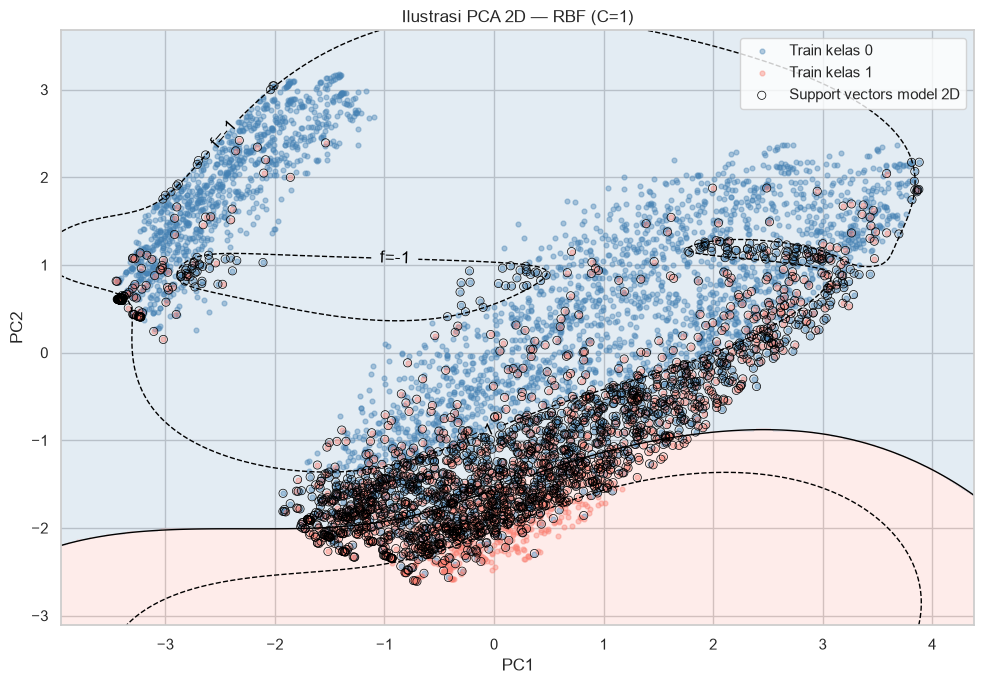

In [19]:
pca = PCA(n_components=2, random_state=RANDOM_STATE)
X_train_2d = pca.fit_transform(X_train_scaled)
X_test_2d = pca.transform(X_test_scaled)
model_2d = clone(model_terbaik)
model_2d.fit(X_train_2d, y_train)
print(f"Varians yang dijelaskan 2 PC: {pca.explained_variance_ratio_.sum():.2%}")
print(f"Akurasi test model ilustratif 2D: {model_2d.score(X_test_2d, y_test):.4f}")
print("Skor dan support vectors model 2D dapat berbeda dari model utama.")

batas_min = X_train_2d.min(axis=0) - 0.5
batas_max = X_train_2d.max(axis=0) + 0.5
xx, yy = np.meshgrid(np.linspace(batas_min[0], batas_max[0], 220),
                    np.linspace(batas_min[1], batas_max[1], 220))
grid = np.c_[xx.ravel(), yy.ravel()]
skor = model_2d.decision_function(grid).reshape(xx.shape)
fig, ax = plt.subplots(figsize=(10, 7))
ax.contourf(xx, yy, (skor >= 0).astype(int), levels=[-0.5, 0.5, 1.5],
            colors=["steelblue", "salmon"], alpha=0.15)
kontur = ax.contour(xx, yy, skor, levels=[-1, 0, 1], colors="black",
                linestyles=["--", "-", "--"], linewidths=1)
ax.clabel(kontur, fmt={-1: "f=-1", 0: "f=0", 1: "f=1"})
for kelas, warna in [(0, "steelblue"), (1, "salmon")]:
    mask = np.asarray(y_train) == kelas
    ax.scatter(X_train_2d[mask, 0], X_train_2d[mask, 1], c=warna, s=12,
            alpha=0.4, label=f"Train kelas {kelas}")
sv = model_2d.support_vectors_
ax.scatter(sv[:, 0], sv[:, 1], facecolors="none", edgecolors="black",
        s=35, linewidths=0.5, label="Support vectors model 2D")
ax.set(title=f"Ilustrasi PCA 2D — {nama_terbaik}", xlabel="PC1", ylabel="PC2")
ax.legend()
plt.tight_layout()
plt.show()


# 5. Analisis

## 5.1 Karakteristik Dataset dan Preprocessing

Dataset Telco Customer Churn terdiri atas **7.043 pelanggan dan 21 kolom**, dengan 5.174 pelanggan bertahan atau **73,46%** dan 1.869 pelanggan churn atau **26,54%**. Distribusi ini menunjukkan ketidakseimbangan kelas, sehingga evaluasi tidak cukup hanya menggunakan accuracy.

Tidak ditemukan baris duplikat. Pemeriksaan awal menunjukkan tidak ada missing value, tetapi konversi `TotalCharges` menjadi numerik mengungkap **11 nilai yang tidak dapat dikonversi**. Nilai tersebut ditangani menggunakan imputasi median dari data train.

Setelah `customerID` dan target dipisahkan, terdapat 19 fitur, yaitu 3 numerik dan 16 kategorikal. One-hot encoding digunakan untuk fitur kategorikal, sedangkan StandardScaler diterapkan pada fitur numerik. Hasil preprocessing menghasilkan **46 fitur**, tanpa missing value pada train maupun test.

Dataset dibagi menjadi **5.634 sampel train dan 1.409 sampel test** menggunakan pembagian 80:20 dengan stratifikasi. Imputer, encoder, dan scaler dipelajari hanya dari data train sehingga tidak terjadi kebocoran informasi test pada tahap preprocessing.

## 5.2 Hubungan Hasil EDA dengan Pemodelan

Histogram dan boxplot menunjukkan bahwa pelanggan churn cenderung memiliki masa berlangganan (`tenure`) lebih pendek, biaya bulanan (`MonthlyCharges`) lebih tinggi, dan total biaya (`TotalCharges`) lebih rendah dibandingkan pelanggan yang bertahan.

Namun, distribusi kedua kelas masih saling tumpang tindih. Artinya, satu fitur numerik saja belum cukup untuk memisahkan pelanggan churn dan bertahan secara sempurna.

Distribusi churn berdasarkan kontrak menunjukkan:

| Jenis kontrak | Pelanggan bertahan | Pelanggan churn |
|---|---:|---:|
| Month-to-month | 57,29% | 42,71% |
| One year | 88,73% | 11,27% |
| Two year | 97,17% | 2,83% |

Kontrak bulanan memiliki proporsi churn tertinggi. Temuan ini menunjukkan adanya hubungan antara jenis kontrak dan churn, tetapi tidak membuktikan bahwa jenis kontrak merupakan penyebab langsung churn.

Tumpang tindih distribusi menjadi alasan untuk membandingkan model dengan batas keputusan linear dan non-linear. Namun, tumpang tindih pada beberapa grafik tidak membuktikan bahwa seluruh fitur tidak dapat dipisahkan secara linear, karena model menggunakan kombinasi 46 fitur hasil preprocessing.

## 5.3 Perbandingan Kernel Linear dan RBF

Kedua model menggunakan `C=1`, sedangkan model RBF menggunakan `gamma='scale'`.

| Kernel | Akurasi train | Akurasi test | Gap train–test |
|---|---:|---:|---:|
| Linear | 80,07% | 78,78% | 1,29 poin persentase |
| RBF | 82,18% | 79,06% | 3,12 poin persentase |

Kernel RBF menghasilkan akurasi test sedikit lebih tinggi dibandingkan Linear. Berdasarkan jumlah prediksi benar, selisihnya hanya **4 pelanggan dari 1.409 sampel test**, atau sekitar **0,28 poin persentase**.

RBF mampu membentuk batas keputusan non-linear sehingga dapat menangkap pola yang tidak dapat direpresentasikan oleh satu hyperplane linear. Namun, peningkatan akurasi train lebih besar daripada peningkatan akurasi test. Gap RBF juga lebih lebar, yang menunjukkan bahwa kemampuan menyesuaikan data train belum sepenuhnya memberikan peningkatan pada data test.

Hasil ini menunjukkan bahwa kernel Linear sudah cukup kompetitif pada konfigurasi yang diuji. Fleksibilitas RBF memberikan keuntungan kecil dalam accuracy, tetapi tidak otomatis meningkatkan seluruh metrik evaluasi.

Perbedaan kedua model **belum dapat disebut signifikan secara statistik**, karena eksperimen hanya menggunakan satu pembagian data dan belum dilakukan pengujian statistik atau pengulangan cross-validation.

## 5.4 Pengaruh Parameter C terhadap Underfitting dan Overfitting

Eksperimen dilakukan menggunakan kernel RBF dengan `gamma='scale'` dan variasi nilai `C`.

| C | Akurasi train | Akurasi test | Gap train–test | Jumlah support vectors |
|---|---:|---:|---:|---:|
| 0,01 | 73,68% | 73,60% | 0,08 poin persentase | 3.013 |
| 0,1 | 80,17% | **79,13%** | 1,04 poin persentase | 2.692 |
| 1 | 82,18% | 79,06% | 3,12 poin persentase | 2.649 |
| 10 | 86,00% | 78,21% | 7,78 poin persentase | 2.718 |
| 100 | **92,65%** | 76,15% | **16,50 poin persentase** | 2.647 |

Gap mengikuti hasil perhitungan sebelum pembulatan sehingga dapat sedikit berbeda dari pengurangan persentase yang ditampilkan.

Pada **`C=0,01`**, akurasi train dan test sama-sama rendah, yaitu sekitar 73,6%. Akurasi test tersebut hampir sama dengan pembanding yang selalu memprediksi kelas mayoritas, yaitu **73,46%**. Hasil ini mengindikasikan underfitting: regularisasi yang kuat membuat model terlalu membatasi penyesuaiannya terhadap pola data. Namun, tanpa distribusi prediksi model tersebut, belum dapat disimpulkan bahwa semua sampel diprediksi sebagai kelas mayoritas.

Peningkatan `C` menjadi **0,1** menaikkan akurasi test menjadi **79,13%**, tertinggi di antara nilai yang diuji. Gap train–test masih relatif kecil, yaitu 1,04 poin persentase.

Saat `C` meningkat menjadi 1, akurasi train naik, tetapi akurasi test sedikit menurun. Pola ini menjadi indikasi awal meningkatnya penyesuaian terhadap train, meskipun penurunan test dari `C=0,1` ke `C=1` hanya setara satu prediksi benar.

Indikasi overfitting menjadi lebih jelas pada **`C=10`** dan terutama **`C=100`**. Akurasi train terus meningkat, sedangkan akurasi test menurun. Pada `C=100`, gap mencapai 16,50 poin persentase.

Secara konsep, nilai `C` yang besar memberikan penalti lebih tinggi terhadap pelanggaran margin dan kesalahan training. Model kemudian lebih berusaha menyesuaikan data train, yang dapat mengurangi kemampuan generalisasi.

Dengan demikian, **`C=0,1` merupakan kandidat terbaik berdasarkan accuracy test pada eksperimen ini**. Namun, keunggulannya atas `C=1` sangat kecil dan masih perlu divalidasi.

Eksperimen ini hanya memvariasikan `C`. Karena `gamma` tetap menggunakan `'scale'` pada data train yang sama, pengaruh perubahan gamma belum diuji secara terpisah.

## 5.5 Evaluasi Metrik dan Confusion Matrix

Evaluasi berikut membandingkan dua model baseline dengan `C=1`.

| Model | Accuracy | Precision churn | Recall churn | F1-score churn |
|---|---:|---:|---:|---:|
| Linear | 78,78% | 61,76% | **52,67%** | **56,85%** |
| RBF | **79,06%** | **63,86%** | 48,66% | 55,24% |

RBF unggul dalam accuracy dan precision, sedangkan Linear unggul dalam recall dan F1-score kelas churn. Oleh karena itu, penentuan model terbaik bergantung pada tujuan evaluasi.

Confusion matrix kedua model adalah:

| Model | TN | FP | FN | TP |
|---|---:|---:|---:|---:|
| Linear | 913 | 122 | 177 | 197 |
| RBF | 932 | 103 | 192 | 182 |

Model Linear berhasil mendeteksi **197 dari 374 pelanggan churn**, sedangkan RBF mendeteksi **182 pelanggan**. Linear mendeteksi 15 pelanggan churn lebih banyak, tetapi juga menghasilkan 19 false positive lebih banyak.

RBF lebih baik dalam mengurangi pelanggan bertahan yang keliru ditandai sebagai churn. Namun, RBF melewatkan 192 pelanggan churn, lebih banyak dibandingkan Linear yang melewatkan 177 pelanggan.

Dalam konteks retensi pelanggan, jika prioritasnya mengurangi pelanggan churn yang terlewat, Linear lebih menarik berdasarkan recall yang lebih tinggi. Jika prioritasnya meningkatkan ketepatan pelanggan yang ditandai berisiko, RBF memiliki precision lebih tinggi. Keputusan akhir perlu mempertimbangkan biaya penawaran retensi dan kerugian akibat pelanggan churn yang tidak terdeteksi.

Kedua model masih melewatkan banyak pelanggan churn. Karena itu, accuracy sekitar 79% belum cukup untuk menyatakan model sudah optimal bagi kebutuhan retensi.

Selain itu, metrik precision, recall, F1-score, dan confusion matrix yang ditampilkan berasal dari **RBF `C=1`**, bukan RBF `C=0,1`. Evaluasi lengkap model `C=0,1` masih diperlukan sebelum menyatakan model tersebut terbaik untuk mendeteksi churn.

## 5.6 Analisis Support Vectors

| Model | Support vectors kelas 0 | Support vectors kelas 1 | Total | Persentase data train |
|---|---:|---:|---:|---:|
| Linear (`C=1`) | 1.288 | 1.284 | 2.572 | 45,65% |
| RBF (`C=1`) | 1.429 | 1.220 | 2.649 | 47,02% |

Model RBF menggunakan **77 support vectors lebih banyak** daripada Linear. Support vectors merupakan sampel dengan koefisien dual tidak nol yang ikut menentukan fungsi keputusan model.

Pada soft-margin SVM, support vectors dapat berada pada margin, di dalam margin, atau menjadi sampel yang salah diklasifikasikan. Karena itu, support vectors tidak selalu hanya berupa titik yang tepat berada di garis margin.

Jumlah support vectors yang besar dapat meningkatkan biaya prediksi pada SVC berbasis kernel. Akan tetapi, jumlahnya **bukan ukuran tunggal kompleksitas batas keputusan**. Kompleksitas juga dipengaruhi jenis kernel, `C`, gamma, dan karakteristik data.

Hal ini terlihat pada eksperimen: model `C=0,01` memiliki support vectors terbanyak, yaitu 3.013, tetapi justru menunjukkan indikasi underfitting. Sebaliknya, `C=100` memiliki 2.647 support vectors dan menunjukkan indikasi overfitting. Jadi, lebih banyak support vectors tidak otomatis berarti model lebih kompleks atau lebih overfit.

## 5.7 Visualisasi Decision Boundary dengan PCA

PCA digunakan untuk mereduksi 46 fitur menjadi dua komponen utama. Kedua komponen menjelaskan **47,45% varians data train**.

Visualisasi memperlihatkan batas keputusan RBF yang melengkung serta banyak titik kedua kelas yang saling tumpang tindih. Garis `f=0` menunjukkan batas keputusan, sedangkan garis `f=-1` dan `f=1` menunjukkan kontur margin dalam representasi model. Untuk RBF, kontur tersebut bukan garis dengan jarak Euclidean konstan dari batas keputusan pada bidang PCA.

Model ilustratif 2D menghasilkan akurasi test **79,28%**. Nilai tersebut sedikit lebih tinggi daripada RBF utama dengan `C=1`, tetapi tidak cukup untuk menyimpulkan bahwa PCA selalu meningkatkan performa.

Model 2D dilatih ulang pada dua komponen PCA, sehingga **bukan visualisasi persis batas keputusan model utama yang menggunakan 46 fitur**. Dengan `gamma='scale'`, nilai gamma juga dihitung ulang dari representasi 2D. Support vectors dan hasil prediksinya karena itu dapat berbeda.

## 5.8 Keterbatasan Eksperimen

Eksperimen menggunakan satu pembagian train–test. Selain itu, akurasi test digunakan untuk membandingkan kernel dan memilih nilai `C`, sehingga test ikut berperan dalam pemilihan konfigurasi.

Akibatnya, skor tersebut merupakan hasil evaluasi eksploratif dan belum menjadi estimasi akhir yang sepenuhnya independen. Untuk mendapatkan penilaian generalisasi yang lebih kuat, pemilihan hyperparameter perlu menggunakan data validasi atau cross-validation, sedangkan test disimpan untuk evaluasi akhir.

# 6. Kesimpulan dan Saran

## 6.1 Kesimpulan

1. Preprocessing menghasilkan **46 fitur**, dengan **5.634 sampel train dan 1.409 sampel test**, tanpa missing value setelah transformasi. Parameter preprocessing dipelajari hanya dari data train.

2. Pada `C=1`, kernel RBF menghasilkan accuracy lebih tinggi, yaitu **79,06%**, dibandingkan Linear sebesar **78,78%**. Namun, selisihnya hanya empat prediksi benar dan belum terbukti signifikan secara statistik.

3. Linear memiliki recall dan F1-score churn lebih tinggi, masing-masing **52,67%** dan **56,85%**, sedangkan RBF memiliki precision lebih tinggi sebesar **63,86%**. Oleh karena itu, model terbaik tidak dapat ditentukan hanya berdasarkan accuracy.

4. Pada eksperimen variasi `C`, nilai **`C=0,1` menghasilkan accuracy test tertinggi sebesar 79,13%**. `C=0,01` menunjukkan indikasi underfitting, sedangkan overfitting semakin jelas pada `C=10` dan `C=100`.

5. RBF menggunakan lebih banyak support vectors daripada Linear, tetapi jumlah support vectors tidak dapat digunakan sebagai satu-satunya indikator kompleksitas atau overfitting.

6. Visualisasi PCA membantu memahami bentuk batas keputusan, tetapi hanya menjelaskan **47,45% varians data** dan menggunakan model 2D yang dilatih terpisah dari model utama.

7. Kemampuan mendeteksi churn masih perlu ditingkatkan karena kedua baseline melewatkan banyak pelanggan churn. Hasil pemilihan model juga perlu dikonfirmasi menggunakan evaluasi yang independen.

## 6.2 Saran

1. **Gunakan cross-validation untuk memilih hyperparameter.**  
   Terapkan StratifiedKFold dan GridSearchCV pada data train. Gabungkan preprocessing dan SVC dalam satu pipeline agar imputasi, encoding, dan scaling di-fit hanya pada bagian training setiap fold.

2. **Uji kombinasi C dan gamma.**  
   Eksperimen saat ini hanya mengubah C. Uji beberapa kombinasi C dan gamma untuk mencari keseimbangan antara kemampuan mempelajari pola dan generalisasi, tanpa menggunakan test sebagai dasar tuning.

3. **Evaluasi lengkap model RBF dengan C=0,1.**  
   Hitung precision, recall, F1-score, dan confusion matrix model tersebut. Accuracy tertinggi belum menjamin kemampuan deteksi churn terbaik.

4. **Pertimbangkan ketidakseimbangan kelas.**  
   Bandingkan penggunaan `class_weight='balanced'` dengan konfigurasi awal melalui validasi. Tujuannya meningkatkan perhatian model terhadap kelas churn, sambil memeriksa kemungkinan kenaikan false positive.

5. **Sesuaikan metrik dan ambang keputusan dengan tujuan retensi.**  
   Gunakan recall, precision, F1-score, dan PR-AUC. Ambang pada `decision_function` dapat diuji menggunakan data validasi untuk mengatur keseimbangan antara pelanggan churn yang terdeteksi dan false positive.

6. **Ulangi eksperimen untuk menilai kestabilan hasil.**  
   Gunakan beberapa pembagian data atau repeated stratified cross-validation, lalu laporkan rata-rata dan penyebaran skor. Hal ini penting karena perbedaan model terbaik sangat kecil.

7. **Bandingkan alternatif model dan reduksi dimensi secara terkontrol.**  
   Bandingkan SVM dengan Logistic Regression, ANN, atau model pohon pada pembagian data yang sama. Jika menguji PCA, pilih jumlah komponen melalui validasi; dua komponen pada notebook terutama digunakan untuk visualisasi.